# Group theory 9: Ruler and compass

*Learning path: group theory, part 9 of 10.* [Index](README.md) · Previous: [Polynomials over fields](08-polynomials-over-fields.ipynb) · Next: [Error-correcting codes](10-error-correcting-codes.ipynb)

**The question.** The Greeks constructed a square root, a regular pentagon and the bisection of any angle with only
an unmarked ruler and a compass. Three problems resisted them for two thousand years: **double the cube** (build a cube
with twice the volume of a given one), **trisect an angle**, and **square the circle**. They are impossible, and the
proofs, found in the 1800s, are not geometry at all: they count the degrees of field extensions. The same count told
the 19-year-old Gauss that a regular 17-gon *can* be constructed, the first new constructible polygon since Euclid.

**Who this is for:** anyone who has done lessons [5](05-rings-and-fields.ipynb) and
[8](08-polynomials-over-fields.ipynb). **You need:** number fields (`numfield`), minimal polynomials, irreducibility.

**You will learn**

* which lengths a ruler and compass can construct: the **constructible numbers**,
* the **degree** of a field extension, and the **tower law** $[L:K] = [L:M][M:K]$,
* why a constructible number has a minimal polynomial of degree $2^k$,
* why doubling the cube and trisecting $60°$ are impossible,
* the **Gauss–Wantzel theorem**: which regular polygons can be constructed, and the 17-gon.

## 1. What a ruler and compass can do

Start with two points at distance 1. A ruler draws the line through two points, a compass a circle with a given
centre through a given point, and new points arise where lines and circles meet. Which lengths can be reached?

Sums, differences, products and quotients of constructible lengths are constructible (similar triangles), so the
constructible numbers form a **field** containing $\mathbb Q$. And square roots are constructible: in a semicircle on a
diameter of length $1 + a$, the perpendicular at the point that splits it into $1$ and $a$ has height $\sqrt a$.

Nothing else is. Intersecting two lines means solving linear equations; intersecting a line with a circle, or two
circles, means solving a **quadratic**. So every new coordinate lies in a field obtained from the previous one by
adjoining one square root. A number is constructible exactly when it is reached from $\mathbb Q$ by a chain of square
roots, like the golden ratio $(1 + \sqrt5)/2$, which builds the pentagon, or

$$\sqrt{2 + \sqrt{2 + \sqrt2}}.$$

## 2. Degrees and the tower law

If $K \subset L$ are fields, $L$ is a vector space over $K$, and its dimension is the **degree** $[L:K]$. For a
number $\alpha$ with minimal polynomial of degree $d$ over $\mathbb Q$, the field $\mathbb Q(\alpha)$ has basis
$1, \alpha, \ldots, \alpha^{d-1}$, so $[\mathbb Q(\alpha):\mathbb Q] = d$.

Take $\alpha = \sqrt2 + \sqrt3$. Its minimal polynomial is $x^4 - 10x^2 + 1$, so $\mathbb Q(\alpha)$ has degree 4. It
contains $\sqrt2$, because $\alpha^3 = 11\sqrt2 + 9\sqrt3$ gives $\sqrt2 = (\alpha^3 - 9\alpha)/2$:

In [1]:
K = numfield(x^4 - 10*x^2 + 1);
a = K(x);
minpoly(a)
minpoly((a^3 - 9*a)/2)

x^4-10*x^2+1

> The monic polynomial of least degree over Q that vanishes at numfield(x^4-10*x^2+1, x); it has degree 4, at most 4, the degree of the ring.

x^2-2

> The monic polynomial of least degree over Q that vanishes at numfield(x^4-10*x^2+1, x^3/2-9*x/2); it has degree 2, at most 4, the degree of the ring.

So $\mathbb Q \subset \mathbb Q(\sqrt2) \subset \mathbb Q(\alpha)$ with degrees 2 and 2, and $4 = 2 \times 2$. That is
the **tower law**: for $K \subset M \subset L$, $[L:K] = [L:M]\,[M:K]$ (a basis of $L$ over $M$ times a basis of $M$
over $K$ is a basis of $L$ over $K$).

Now the key consequence. Each square root step has degree 1 or 2, so a constructible number lies in a field of degree
$2^k$ over $\mathbb Q$, and by the tower law the degree of its own minimal polynomial **divides** $2^k$:

> A constructible number has a minimal polynomial over $\mathbb Q$ whose degree is a power of 2.

**Try this.** Find the minimal polynomial of $\sqrt3 = (\alpha^3 - 11\alpha)/(-2)$ in `K`. (Check the formula first by
expanding $\alpha^3$.)

## 3. Two impossible problems

**Doubling the cube.** A cube of volume 2 has side $\sqrt[3]2$, a root of $x^3 - 2$. That is irreducible (Eisenstein
with $p = 2$), so its degree is 3, not a power of 2. **Impossible.**

In [2]:
factor(x^3 - 2)

x^3-2

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

**Trisecting an angle.** Some angles can be trisected (90° into 30°). But a $60°$ angle is easy to construct, and
trisecting it means constructing $\cos 20°$. The triple-angle formula $\cos 3\theta = 4\cos^3\theta - 3\cos\theta$
with $\cos 60° = \tfrac12$ makes $c = \cos 20°$ a root of $8c^3 - 6c - 1$:

In [3]:
solve(8*x^3 - 6*x - 1, x)
factor(8*x^3 - 6*x - 1)

[cos(11*pi/9), cos(5*pi/9), cos(pi/9)]

> **Cubic formula (Cardano)** for `8*x^3-6*x-1` = 0. With x = t it reads t^3 + p·t + q = 0 with p = `-3/4`, q = `-1/8`; D = (q/2)^2 + (p/3)^3 = `-3/256`. D < 0: three real roots. Cardano's sqrt(D) would be imaginary, so they are written with cos instead.

8*x^3-6*x-1

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

Its roots are $\cos 20°$, $\cos 100°$ and $\cos 220°$, and it has no rational root (the candidates $\pm1, \pm\tfrac12,
\pm\tfrac14, \pm\tfrac18$ all fail), so being a cubic it is irreducible: degree 3, and $\cos 20°$ is not constructible.
There is no general method to trisect an angle with ruler and compass. Pierre Wantzel published both proofs in 1837.

**Squaring the circle** needs $\sqrt\pi$, and Lindemann proved in 1882 that $\pi$ is not a root of *any* polynomial with
rational coefficients (it is **transcendental**), so it is not constructible either.

## 4. Regular polygons

A regular $n$-gon is constructible exactly when $\cos(2\pi/n)$ is. That number has degree $\varphi(n)/2$ over
$\mathbb Q$ (for $n \ge 3$), where $\varphi$ is Euler's function, because its Galois group is the group of units
mod $n$ divided by $\pm1$. The degree must be a power of 2, and Gauss showed the converse: then the Galois group is an
abelian 2-group, which has a chain of subgroups of index 2, which gives a chain of square roots. So the
**Gauss–Wantzel theorem**: the $n$-gon is constructible exactly when $\varphi(n)$ is a power of 2.

In [4]:
function pow2(m)
  while mod(m, 2) == 0
    m = m/2;
  end
  return m == 1
end
ok = [];
for n in 3:100
  if pow2(eulerphi(n))
    ok = append(ok, n);
  end
end
ok

[3, 4, 5, 6, 8, 10, 12, 15, 16, 17, 20, 24, 30, 32, 34, 40, 48, 51, 60, 64, 68, 80, 85, 96]

That happens when $n$ is a power of 2 times distinct **Fermat primes** $2^{2^k} + 1$: 3, 5, 17, 257 and 65537 are
the only ones known. The heptagon is not on the list. Its $2\cos(2\pi/7)$ is a root of a cubic whose Galois group is
the cyclic group of order 3, not a 2-group:

In [5]:
galois(x^3 + x^2 - 2*x - 1)

alt(3)

> The Galois group of x^3+x^2-2*x-1 over Q, acting on its 3 roots, has order 3. The discriminant 49 is a square, so the group lies inside A3. Every group here is solvable, so the roots are expressible by radicals: solve gives them (Cardano for degree 3, Ferrari for 4).

**The 17-gon.** $\varphi(17) = 16 = 2^4$, so four square roots must suffice, and Gauss found them in 1796:

$$\cos\frac{2\pi}{17} = -\frac1{16} + \frac{\sqrt{17}}{16} + \frac{\sqrt{34 - 2\sqrt{17}}}{16}
+ \frac18\sqrt{17 + 3\sqrt{17} - \sqrt{34 - 2\sqrt{17}} - 2\sqrt{34 + 2\sqrt{17}}}.$$

In [6]:
c17 = -1/16 + sqrt(17)/16 + sqrt(34 - 2*sqrt(17))/16 + sqrt(17 + 3*sqrt(17) - sqrt(34 - 2*sqrt(17)) - 2*sqrt(34 + 2*sqrt(17)))/8;
eval([c17, cos(2*pi/17)], 15)

[0.932472229404356, 0.932472229404356]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

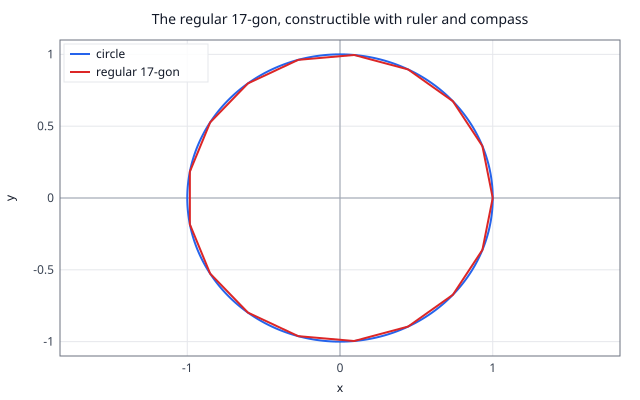

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
X = []; Y = [];
for k in 0:17
  X = append(X, cos(2*pi*k/17)); Y = append(Y, sin(2*pi*k/17));
end
p = parametric(cos(t), sin(t), t, 0, 2*pi);
p = show(p, plot(X, Y));
p = legend(p, "circle", "regular 17-gon");
labels(title(p, "The regular 17-gon, constructible with ruler and compass"), "x", "y")

Gauss asked for a 17-gon on his tombstone. The stonemason refused, saying it would look like a circle. The 257-gon
was constructed by Richelot in 1832, and Johann Hermes spent ten years on the 65537-gon; his manuscript fills a
suitcase in Göttingen.

**Try this.** Is the regular 51-gon constructible? The 63-gon? Explain with $\varphi$.

## Exercises

1. **Constructible.** Show that $\sqrt{2 + \sqrt2}$ is constructible, and find its minimal polynomial. (Square twice.)
2. **Not constructible.** Is $\sqrt[4]{2}$ constructible? Is $\sqrt[6]{2}$?
3. **Tower law.** Use the tower law to show that $\sqrt[3]2 \notin \mathbb Q(\sqrt2, \sqrt3)$.
4. **Trisecting 90°.** Show that $90°$ can be trisected, and explain why that doesn't contradict section 3.
5. **Pentagon.** Show that $2\cos 72°$ is a root of $x^2 + x - 1$, and so the pentagon is constructible.
6. **Fermat primes.** Check with `factor` that $2^{32} + 1$ is not prime (Euler, 1732). Which $n$-gons would be
   constructible if it were?

## Summary

* Ruler and compass construct exactly the numbers reached from $\mathbb Q$ by field operations and square roots.
* $[\mathbb Q(\alpha):\mathbb Q]$ is the degree of the minimal polynomial; degrees multiply in towers.
* A constructible number has degree $2^k$: doubling the cube (degree 3) and trisecting $60°$ (degree 3) are impossible;
  squaring the circle fails because $\pi$ is transcendental.
* The regular $n$-gon is constructible exactly when $\varphi(n)$ is a power of 2; the 17-gon is the first new one
  after the Greeks.

## Hints and answers

* **Section 2, Try this.** $x^2 - 3$. ($\alpha^3 = 11\sqrt2 + 9\sqrt3$ and $\alpha = \sqrt2 + \sqrt3$, so
  $\alpha^3 - 11\alpha = -2\sqrt3$.)
* **Section 4, Try this.** $\varphi(51) = 32$: yes (51 = 3 · 17). $\varphi(63) = 36$: no.
* **Exercise 1.** $x^2 = 2 + \sqrt2$, so $(x^2 - 2)^2 = 2$: $x^4 - 4x^2 + 2$, irreducible by Eisenstein. Degree 4.
* **Exercise 2.** $\sqrt[4]2 = \sqrt{\sqrt2}$ is constructible. $\sqrt[6]2$ has minimal polynomial $x^6 - 2$
  (Eisenstein): degree 6, not constructible.
* **Exercise 3.** $\mathbb Q(\sqrt2, \sqrt3)$ has degree 4. If it contained $\sqrt[3]2$, then 3 would divide 4.
* **Exercise 4.** $30°$ is constructible (half an equilateral triangle). The theorem says no method works for *every*
  angle, not that no angle can be trisected.
* **Exercise 5.** With $c = 2\cos72°$, $\zeta = e^{2\pi i/5}$ satisfies $\zeta^4 + \zeta^3 + \zeta^2 + \zeta + 1 = 0$;
  divide by $\zeta^2$ and use $c = \zeta + \zeta^{-1}$.
* **Exercise 6.** `factor(2^32 + 1)` gives $641 \times 6700417$. Products of a power of 2 with distinct numbers among
  3, 5, 17, 257, 65537 and $2^{32} + 1$.

## Sources

1. P. L. Wantzel, "Recherches sur les moyens de reconnaître si un problème de géométrie peut se résoudre avec la règle
   et le compas", *Journal de Mathématiques Pures et Appliquées* 2, 366–372 (1837).
2. C. F. Gauss, *Disquisitiones Arithmeticae* (1801), section VII.
3. F. Lindemann, "Über die Zahl π", *Mathematische Annalen* 20, 213–225 (1882).
4. I. Stewart, *Galois Theory*, 4th ed., CRC Press (2015), chapters 7 and 19.